<a href="https://colab.research.google.com/github/amrutapsonar-cell/AMRUTA/blob/main/sentiment_analysis_nlp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install textblob

In [ ]:
!pip install finnhub-python

import finnhub
import pandas as pd
from datetime import datetime, timedelta
from textblob import TextBlob
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import nltk

nltk.download('vader_lexicon', quiet=True)

# 1. Configuration
# WARNING: Replace 'YOUR_ACTUAL_API_KEY_HERE' with your real Finnhub API Key
from google.colab import userdata
API_KEY = userdata.get('FINHUB').strip()
TICKER = 'AAPL'

# Automatically set range to the last 7 days to avoid historical limits
END_DATE = datetime.today().strftime('%Y-%m-%d')
START_DATE = (datetime.today() - timedelta(days=7)).strftime('%Y-%m-%d')

print(f"Fetching news for {TICKER} from {START_DATE} to {END_DATE}...")

finn_client = finnhub.Client(api_key=API_KEY)
news_raw = finn_client.company_news(TICKER, _from=START_DATE, to=END_DATE)

df = pd.DataFrame(news_raw)

# 2. Check and Handle Empty Data
if df.empty:
    print("\n[!] Error: The API returned no news articles.")
    print("Troubleshooting steps:")
    print("1. Double-check that your API_KEY is correct.")
    print("2. Free tier accounts may restrict historical data; using a recent 7-day window usually fixes this.")
    print("3. Ensure you haven't exceeded FinnHub's rate limit (60 calls/minute).")
else:
    print(f"Successfully fetched {len(df)} articles!\n")

    # Find timestamp column safely
    possible_time_cols = ['time', 'datetime', 'publishedAt']
    time_col = next((col for col in possible_time_cols if col in df.columns), None)

    if time_col:
        df['datetime'] = pd.to_datetime(df[time_col], unit='s' if df[time_col].dtype in ['int64', 'float64'] else None)
        df['date'] = df['datetime'].dt.date
    else:
        df['date'] = datetime.today().date()

    # Clean text fields
    headline_col = 'headline' if 'headline' in df.columns else df.columns[0]
    summary_col = 'summary' if 'summary' in df.columns else ''

    df['summary'] = df[summary_col].fillna('') if summary_col else ''
    df['full_text'] = df[headline_col].astype(str) + '. ' + df['summary'].astype(str)

    # Sentiment Analysis
    vader = SentimentIntensityAnalyzer()
    df['vader_compound'] = df['full_text'].apply(lambda x: vader.polarity_scores(str(x))['compound'])
    df['textblob_polarity'] = df['full_text'].apply(lambda x: TextBlob(str(x)).sentiment.polarity)

    def classify_sentiment(score):
        if score >= 0.05:
            return 'Positive'
        elif score <= -0.05:
            return 'Negative'
        else:
            return 'Neutral'

    df['sentiment_class'] = df['vader_compound'].apply(classify_sentiment)

    # Output results
    print(df[['date', headline_col, 'vader_compound', 'sentiment_class']].head())

Fetching news for AAPL from 2026-10-22 to 2026-10-29...
Successfully fetched 247 articles!

         date                                           headline  \
0  2026-10-29  Warren Buffett's $48 Billion American Express ...   
1  2026-10-29  How Garmin CEO Cliff Pemble Showed No Fear Nav...   
2  2026-10-29  Omdia: Global Smartphone Shipments Fell 20% in...   
3  2026-10-29  Apple Earnings Preview: Great Cash Flow, But $...   
4  2026-10-29  Meta: Strong Quarter, Bright Outlook, But What...   

   vader_compound sentiment_class  
0          0.7269        Positive  
1         -0.5994        Negative  
2         -0.4939        Negative  
3          0.7808        Positive  
4          0.7579        Positive  


In [ ]:
# 5. Aggregations & Daily Summaries (Now safe since 'date' is guaranteed to exist)
daily_summary = df.groupby('date').agg(
        avg_vader_score=('vader_compound', 'mean'),
        avg_textblob_score=('textblob_polarity', 'mean'),
        article_count=(headline_col, 'count')
    ).reset_index()

print("\n--- Sample Processed Headings ---")
print(df[['date', headline_col, 'vader_compound', 'sentiment_class']].head())
print("\n--- Sentiment Class Distribution ---")
print(df['sentiment_class'].value_counts())


--- Sample Processed Headings ---
         date                                           headline  \
0  2026-10-29  Warren Buffett's $48 Billion American Express ...   
1  2026-10-29  How Garmin CEO Cliff Pemble Showed No Fear Nav...   
2  2026-10-29  Omdia: Global Smartphone Shipments Fell 20% in...   
3  2026-10-29  Apple Earnings Preview: Great Cash Flow, But $...   
4  2026-10-29  Meta: Strong Quarter, Bright Outlook, But What...   

   vader_compound sentiment_class  
0          0.7269        Positive  
1         -0.5994        Negative  
2         -0.4939        Negative  
3          0.7808        Positive  
4          0.7579        Positive  

--- Sentiment Class Distribution ---
sentiment_class
Positive    141
Negative     57
Neutral      49
Name: count, dtype: int64


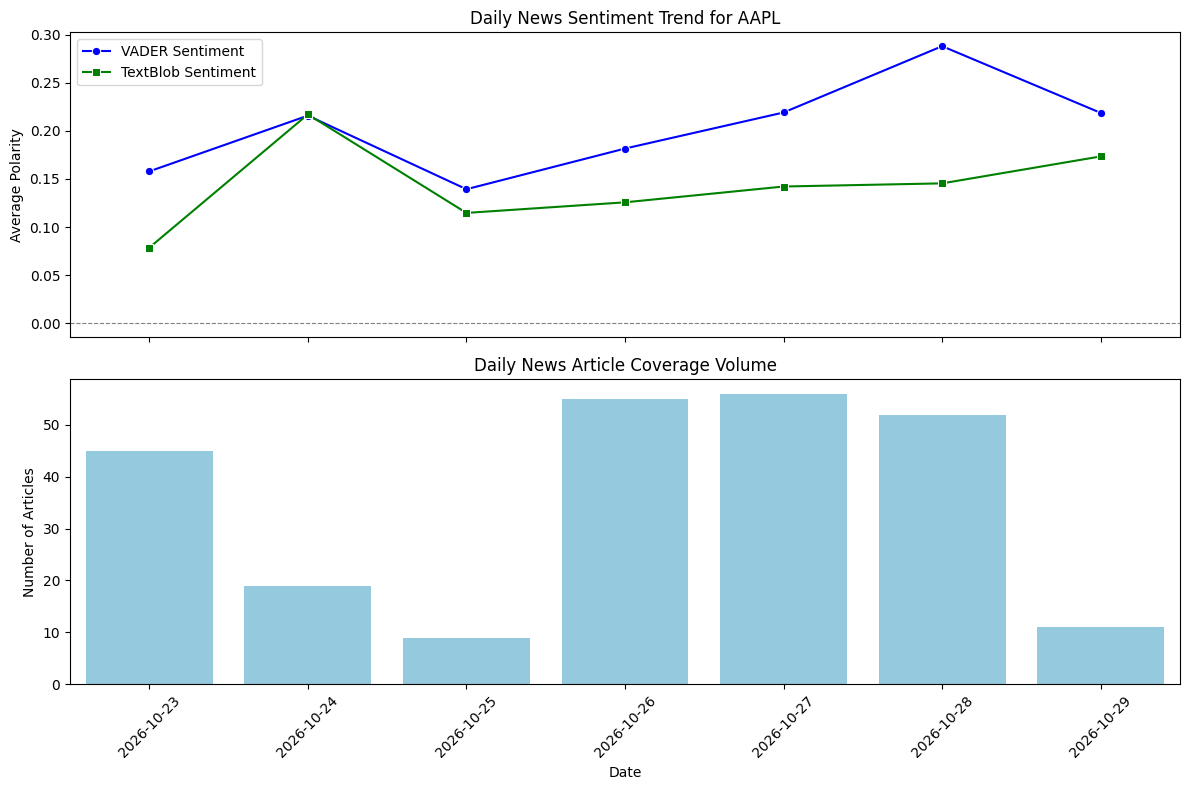

In [ ]:
# 6. Visualizations
daily_summary['date_str'] = daily_summary['date'].astype(str)

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

sns.lineplot(data=daily_summary, x='date_str', y='avg_vader_score', ax=axes[0], marker='o', color='b', label='VADER Sentiment')
sns.lineplot(data=daily_summary, x='date_str', y='avg_textblob_score', ax=axes[0], marker='s', color='g', label='TextBlob Sentiment')
axes[0].axhline(0, color='gray', linestyle='--', linewidth=0.8)
axes[0].set_title('Daily News Sentiment Trend for AAPL')
axes[0].set_ylabel('Average Polarity')
axes[0].legend()

sns.barplot(data=daily_summary, x='date_str', y='article_count', ax=axes[1], color='skyblue')
axes[1].set_title('Daily News Article Coverage Volume')
axes[1].set_ylabel('Number of Articles')
axes[1].set_xlabel('Date')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Sentiment Validation against Labelled Financial Examples
labelled_examples = [
    ("Apple reports record fourth-quarter revenue and strong iPhone demand.", "Positive"),
    ("Shares of Apple surged 5% after beating Wall Street earnings expectations.", "Positive"),
    ("Company announces massive stock buyback and increases quarterly dividend.", "Positive"),
    ("Strong growth in services division boosts overall profit margins.", "Positive"),
    ("Analysts upgrade stock rating to buy following breakthrough product launch.", "Positive"),
    ("Apple faces antitrust lawsuit and potential hefty regulatory fines.", "Negative"),
    ("Supply chain disruptions cause significant delays in iPhone production.", "Negative"),
    ("Shares plummet after company issues disappointing revenue guidance.", "Negative"),
    ("Slumping sales in key international markets weigh heavily on quarterly earnings.", "Negative"),
    ("Investors worry as rising interest rates and inflation hurt tech spending.", "Negative"),
    ("Apple schedules its annual shareholder meeting for next month.", "Neutral"),
    ("Here is how many shares of Apple stock you would need to equal $10,000.", "Neutral"),
    ("Company files routine quarterly financial report with the SEC.", "Neutral"),
    ("Tech executives to attend upcoming industry conference in San Francisco.", "Neutral"),
    ("Market awaits Federal Reserve announcement on Wednesday afternoon.", "Neutral")
]

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as tf_sns

val_df = pd.DataFrame(labelled_examples, columns=['text', 'true_label'])
val_df['vader_score'] = val_df['text'].apply(lambda x: vader.polarity_scores(x)['compound'])
val_df['vader_pred'] = val_df['vader_score'].apply(classify_sentiment)

val_df['textblob_score'] = val_df['text'].apply(lambda x: TextBlob(x).sentiment.polarity)
val_df['textblob_pred'] = val_df['textblob_score'].apply(classify_sentiment)

vader_acc = accuracy_score(val_df['true_label'], val_df['vader_pred'])
tb_acc = accuracy_score(val_df['true_label'], val_df['textblob_pred'])

print(f"=== VADER Sentiment Accuracy: {vader_acc:.2%} ===")
print(classification_report(val_df['true_label'], val_df['vader_pred'], zero_division=0))

print(f"=== TextBlob Sentiment Accuracy: {tb_acc:.2%} ===")
print(classification_report(val_df['true_label'], val_df['textblob_pred'], zero_division=0))

=== VADER Sentiment Accuracy: 60.00% ===
              precision    recall  f1-score   support

    Negative       0.80      0.80      0.80         5
     Neutral       0.50      0.60      0.55         5
    Positive       0.50      0.40      0.44         5

    accuracy                           0.60        15
   macro avg       0.60      0.60      0.60        15
weighted avg       0.60      0.60      0.60        15

=== TextBlob Sentiment Accuracy: 46.67% ===
              precision    recall  f1-score   support

    Negative       0.67      0.40      0.50         5
     Neutral       0.38      0.60      0.46         5
    Positive       0.50      0.40      0.44         5

    accuracy                           0.47        15
   macro avg       0.51      0.47      0.47        15
weighted avg       0.51      0.47      0.47        15

